# Step 1: First look at the IBM HR Attrition data

Goal: understand the data before modeling.
1. Load and check size
2. Check target balance
3. Find useless columns
4. Check missing values
5. Attrition rate and group size by category
6. Check skew

In [3]:
!pip3 install pandas


In [5]:
import sys
print(sys.executable)
%pip install "people-analytics-toolkit[all]" "setuptools<80"

/Users/fatmanoor/Desktop/Fatma_GSU/Sam_tritto_resume_classification/hr_toolkit/.venv_hr/bin/python
  Using cached setuptools-79.0.1-py3-none-any.whl.metadata (6.5 kB)
  Using cached people_analytics_toolkit-0.1.0-py3-none-any.whl.metadata (53 kB)
  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
  Using cached pingouin-0.6.1-py3-none-any.whl.metadata (19 kB)
  Using cached scikit_learn-1.7.2-cp310-cp310-macosx_12_0_arm64.whl.metadata (11 kB)
  Using cached scipy-1.15.3-cp310-cp310-macosx_14_0_arm64.whl.metadata (61 kB)
  Using cached statsmodels-0.15.0-cp310-cp310-macosx_11_0_arm64.whl.metadata (9.6 kB)
  Using cached arch-8.0.0-cp310-cp310-macosx_11_0_arm64.whl.metadata (13 kB)
  Using cached hmmlearn-0.3.3-cp310-cp310-macosx_10_9_universal2.whl.metadata (3.0 kB)
  Using cached lifelines-0.30.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached lightgbm-4.7.0-py3-none-macosx_12_0_arm64.whl.metadata (18 kB)
  Using cached pyod-3.6.7-py3-none-any.whl.metadata (59 kB)
  Usi

In [1]:
# Check that the right environment is active and the toolkit is installed
import sys
import pandas as pd
import people_analytics_toolkit

print("Python:", sys.executable)   # should point inside .venv
print("pandas:", pd.__version__)
print("toolkit imported OK")

Python: /Users/fatmanoor/Desktop/Fatma_GSU/Sam_tritto_resume_classification/hr_toolkit/.venv_hr/bin/python
pandas: 2.3.3
toolkit imported OK


In [2]:
# 1. Load the data (CSV is in the same folder as this notebook)
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Shape:", df.shape)
print(df.dtypes.value_counts())
df.head()

Shape: (1470, 35)
int64     26
object     9
Name: count, dtype: int64


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [8]:
# 2. Target balance: what share of people left?
df["Attrition"].value_counts(normalize=True).round(3)

Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64

In [12]:
# 3. Columns with very few unique values (one value = useless)
df.nunique().sort_values()

StandardHours                  1
Over18                         1
EmployeeCount                  1
left                           2
Attrition                      2
PerformanceRating              2
OverTime                       2
Gender                         2
MaritalStatus                  3
Department                     3
BusinessTravel                 3
EnvironmentSatisfaction        4
StockOptionLevel               4
JobInvolvement                 4
JobSatisfaction                4
RelationshipSatisfaction       4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age       

In [5]:
# 4. Missing values
print("Total missing values:", df.isna().sum().sum())

Total missing values: 0


In [10]:
# 5. Attrition rate and group size by category
df["left"] = (df["Attrition"] == "Yes").astype(int)

for col in ["OverTime", "Department", "JobRole"]:
    summary = df.groupby(col)["left"].agg(rate="mean", count="size").round(3)
    print(f"--- {col} ---")
    print(summary.sort_values("rate", ascending=False), "\n")

--- OverTime ---
           rate  count
OverTime              
Yes       0.305    416
No        0.104   1054 

--- Department ---
                         rate  count
Department                          
Sales                   0.206    446
Human Resources         0.190     63
Research & Development  0.138    961 

--- JobRole ---
                            rate  count
JobRole                                
Sales Representative       0.398     83
Laboratory Technician      0.239    259
Human Resources            0.231     52
Sales Executive            0.175    326
Research Scientist         0.161    292
Healthcare Representative  0.069    131
Manufacturing Director     0.069    145
Manager                    0.049    102
Research Director          0.025     80 



In [11]:
# 6. Skew (0 = symmetric, above ~1 = strongly lopsided)
df[["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]].skew().round(2)

MonthlyIncome        1.37
YearsAtCompany       1.76
TotalWorkingYears    1.12
dtype: float64

In [13]:
cols = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]
pd.DataFrame({"mean": df[cols].mean(), "median": df[cols].median()}).round(1)

,mean,median
MonthlyIncome,6502.9,4919.0
YearsAtCompany,7.0,5.0
TotalWorkingYears,11.3,10.0


array([[<Axes: title={'center': 'MonthlyIncome'}>,
        <Axes: title={'center': 'YearsAtCompany'}>,
        <Axes: title={'center': 'TotalWorkingYears'}>]], dtype=object)

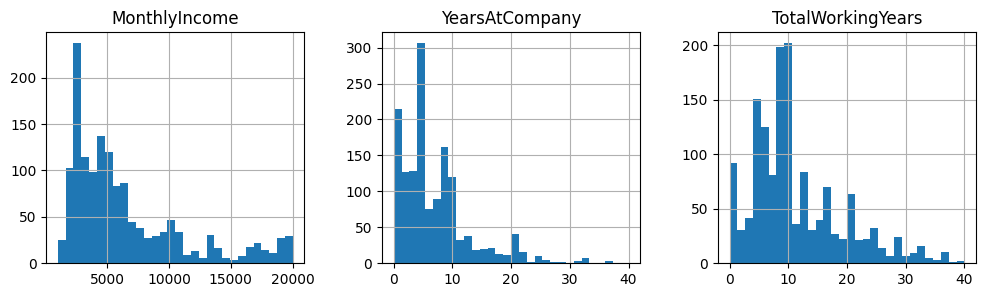

In [14]:
df[cols].hist(bins=30, figsize=(12, 3), layout=(1, 3))